# Khmer Handwriting Recognition  

## Train the Classical CNN

In [6]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

sys.path.insert(0, str(Path("../../src").resolve()))
from cnn_model import CnnFeatureExtractor  # noqa: E402
from config import CLASSICAL_MODELS_DIR, IMG_HEIGHT, IMG_WIDTH  # noqa: E402

SYNTH_DIR = Path("../../data/synthetic_alphabet")
READY_DIR = Path("../../data/3_ready/cnn_alphabet")
CHARTS_DIR = Path("../../results/charts/training")
TABLES_DIR = Path("../../results/tables/training")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

QUBIT_SIZES = [4, 6, 8]
BASELINE_FEATURES = 64
MAX_EPOCHS = 60
PATIENCE = 15
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0
torch.manual_seed(SEED)

with open(SYNTH_DIR / "chars.json", encoding="utf-8") as f:
    chars_info = json.load(f)
SUBSET_16 = chars_info["subset_16"]

df = pd.read_parquet(READY_DIR / "cleaned_dataset.parquet")
print(f"rows: {len(df)}, classes: {df['text'].nunique()}")
df["split"].value_counts()

rows: 2640, classes: 33


split
train    1848
test      396
val       396
Name: count, dtype: int64

## CNN architecture is defined in src/cnn_model.py (shared with the backend) 

In [7]:
def accuracy(logits, labels):
    return float((logits.argmax(dim=1) == labels).float().mean())

## Train one CNN per qubit count, plus the shared classical baseline

In [8]:
def build_tensors(sub_df, label_map):
    flat = np.stack(sub_df["cleaned"].to_numpy())  # saved flattened -- parquet can't hold 2D arrays
    images = torch.tensor(flat.reshape(-1, IMG_HEIGHT, IMG_WIDTH), dtype=torch.float32).unsqueeze(1)
    labels = torch.tensor(sub_df["text"].map(label_map).to_numpy(), dtype=torch.long)
    return images, labels


def train_one_cnn(name, n_features, classes):
    label_map = {ch: i for i, ch in enumerate(classes)}
    n_classes = len(classes)

    sub_df = df[df["text"].isin(classes)]
    X_train, y_train = build_tensors(sub_df[sub_df["split"] == "train"], label_map)
    X_val, y_val = build_tensors(sub_df[sub_df["split"] == "val"], label_map)
    X_test, y_test = build_tensors(sub_df[sub_df["split"] == "test"], label_map)
    print(f"[{name}] features={n_features} classes={n_classes} train={len(X_train)} val={len(X_val)} test={len(X_test)}")

    torch.manual_seed(SEED)
    model = CnnFeatureExtractor(n_features, n_classes)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.CrossEntropyLoss()
    rng = np.random.default_rng(SEED)

    best_val_acc = -1.0
    best_state = None
    best_epoch = 0
    epochs_without_improve = 0
    history = []
    n_train = len(X_train)

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = rng.permutation(n_train)
        epoch_losses = []
        for start in range(0, n_train, BATCH_SIZE):
            idx = perm[start:start + BATCH_SIZE]
            xb, yb = X_train[idx], y_train[idx]
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_acc = accuracy(model(X_val), y_val)
        train_loss = float(np.mean(epoch_losses))
        history.append({"model": name, "epoch": epoch, "train_loss": train_loss, "val_accuracy": val_acc})
        print(f"[{name}] epoch {epoch:2d}  train_loss={train_loss:.4f}  val_acc={val_acc:.3f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_epoch = epoch
            epochs_without_improve = 0
        else:
            epochs_without_improve += 1
            if epochs_without_improve >= PATIENCE:
                print(f"[{name}] early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(model(X_test), y_test)

    model_dir = CLASSICAL_MODELS_DIR / name
    model_dir.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, model_dir / "cnn.pt")
    with open(model_dir / "label_map.json", "w", encoding="utf-8") as f:
        json.dump(label_map, f, ensure_ascii=False, indent=2)

    print(f"[{name}] DONE -> best_epoch={best_epoch} val_acc={best_val_acc:.3f} test_acc={test_acc:.3f}\n")
    summary = {
        "model": name,
        "n_features": n_features,
        "n_classes": n_classes,
        "best_epoch": best_epoch,
        "best_val_accuracy": round(best_val_acc, 4),
        "test_accuracy": round(test_acc, 4),
    }
    return history, summary

In [9]:
all_history = []
summary_rows = []

for n_qubits in QUBIT_SIZES:
    classes = sorted(SUBSET_16) if n_qubits == 4 else sorted(chars_info["all_chars"])
    history, summary = train_one_cnn(f"{n_qubits}q", n_qubits, classes)
    all_history.extend(history)
    summary_rows.append(summary)

history, summary = train_one_cnn("baseline", BASELINE_FEATURES, sorted(chars_info["all_chars"]))
all_history.extend(history)
summary_rows.append(summary)

pd.DataFrame(summary_rows)

[4q] features=4 classes=16 train=896 val=192 test=192
[4q] epoch  1  train_loss=2.7363  val_acc=0.151
[4q] epoch  2  train_loss=2.4099  val_acc=0.328
[4q] epoch  3  train_loss=1.8778  val_acc=0.448
[4q] epoch  4  train_loss=1.5005  val_acc=0.599
[4q] epoch  5  train_loss=1.2019  val_acc=0.646
[4q] epoch  6  train_loss=0.9740  val_acc=0.740
[4q] epoch  7  train_loss=0.8628  val_acc=0.724
[4q] epoch  8  train_loss=0.7470  val_acc=0.786
[4q] epoch  9  train_loss=0.6136  val_acc=0.771
[4q] epoch 10  train_loss=0.5462  val_acc=0.828
[4q] epoch 11  train_loss=0.4710  val_acc=0.880
[4q] epoch 12  train_loss=0.4629  val_acc=0.880
[4q] epoch 13  train_loss=0.4330  val_acc=0.906
[4q] epoch 14  train_loss=0.3451  val_acc=0.901
[4q] epoch 15  train_loss=0.3289  val_acc=0.911
[4q] epoch 16  train_loss=0.3049  val_acc=0.849
[4q] epoch 17  train_loss=0.2679  val_acc=0.906
[4q] epoch 18  train_loss=0.2453  val_acc=0.901
[4q] epoch 19  train_loss=0.2315  val_acc=0.911
[4q] epoch 20  train_loss=0.2508  

,model,n_features,n_classes,best_epoch,best_val_accuracy,test_accuracy
0,4q,4,16,48,0.9635,0.9583
1,6q,6,33,52,0.9192,0.9444
2,8q,8,33,34,0.9419,0.9444
3,baseline,64,33,38,0.9495,0.9318


## Save training curves

In [11]:
with open(TABLES_DIR / "cnn_alphabet_training_history.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["model", "epoch", "train_loss", "val_accuracy"])
    writer.writeheader()
    writer.writerows(all_history)

with open(TABLES_DIR / "cnn_alphabet_training_summary.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f, fieldnames=["model", "n_features", "n_classes", "best_epoch", "best_val_accuracy", "test_accuracy"]
    )
    writer.writeheader()
    writer.writerows(summary_rows)

print("Wrote:", CLASSICAL_MODELS_DIR)
print("Wrote:", TABLES_DIR / "cnn_alphabet_training_summary.csv")

Wrote: D:\Cadt\Year4\Quantum Computing\Khmer_Handwriting_Recognition\models\classical
Wrote: ..\..\results\tables\training\cnn_alphabet_training_summary.csv


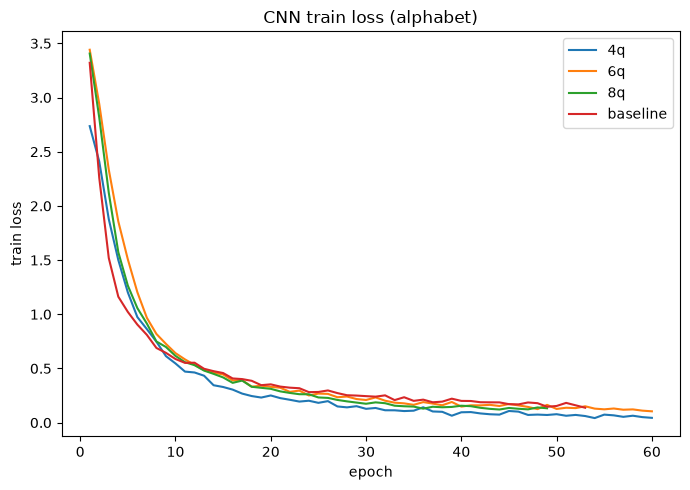

Wrote: ..\..\results\charts\training\cnn_alphabet_training_loss.png


In [12]:
plt.figure(figsize=(7, 5))
for name in [row["model"] for row in summary_rows]:
    rows = [h for h in all_history if h["model"] == name]
    epochs = [r["epoch"] for r in rows]
    plt.plot(epochs, [r["train_loss"] for r in rows], label=name)
plt.title("CNN train loss (alphabet)")
plt.xlabel("epoch")
plt.ylabel("train loss")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "cnn_alphabet_training_loss.png", dpi=150)
plt.show()

print("Wrote:", CHARTS_DIR / "cnn_alphabet_training_loss.png")

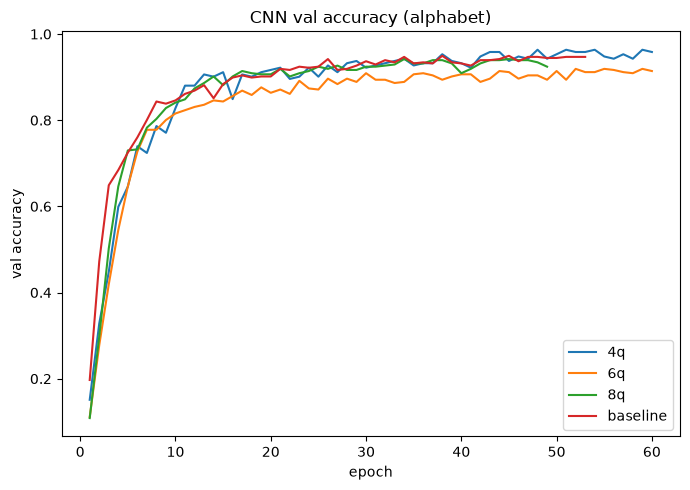

Wrote: ..\..\results\charts\training\cnn_alphabet_val_accuracy.png


In [13]:
plt.figure(figsize=(7, 5))
for name in [row["model"] for row in summary_rows]:
    rows = [h for h in all_history if h["model"] == name]
    epochs = [r["epoch"] for r in rows]
    plt.plot(epochs, [r["val_accuracy"] for r in rows], label=name)
plt.title("CNN val accuracy (alphabet)")
plt.xlabel("epoch")
plt.ylabel("val accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "cnn_alphabet_val_accuracy.png", dpi=150)
plt.show()

print("Wrote:", CHARTS_DIR / "cnn_alphabet_val_accuracy.png")